#Домашка_4

###Бганцова Полина Б06-304в

## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [2]:
%pip install -q "pandas==2.2.3" "scanpy==1.11.5" "anndata==0.11.4" scikit-misc leidenalg igraph

In [3]:
import pandas as pd
import scanpy as sc
import anndata as ad

print("Pandas:", pd.__version__)
print("Scanpy:", sc.__version__)
print("AnnData:", ad.__version__)

Pandas: 2.2.3
Scanpy: 1.11.5
AnnData: 0.11.4


/tmp/ipykernel_1603/1843666085.py:6: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


In [4]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  16.8M      0 --:--:-- --:--:-- --:--:-- 16.8M


In [5]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [6]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [7]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

In [8]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [9]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [10]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [11]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='object')

# Какие есть ещё поля в AnnData?

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [12]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [13]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

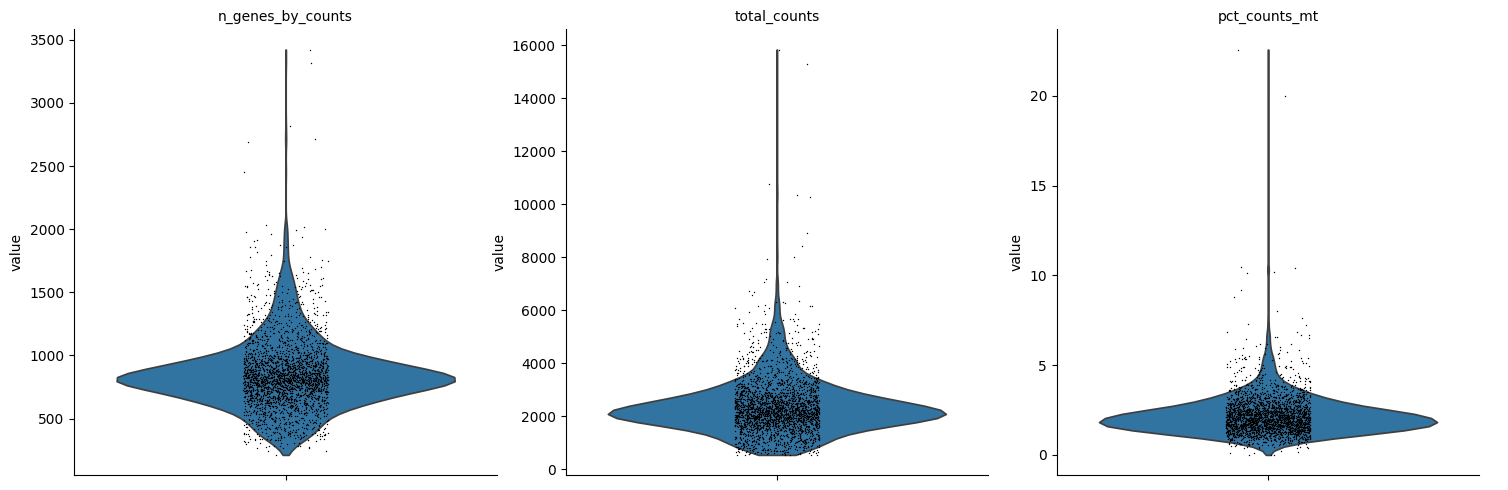

In [14]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [15]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [16]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [17]:
adata.layers["counts"] = adata.X.copy()

In [18]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'

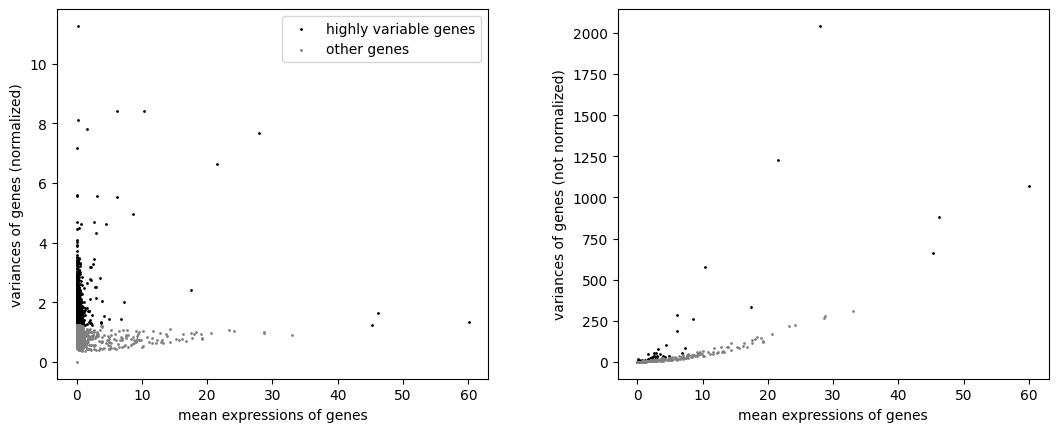

In [19]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: 'counts'

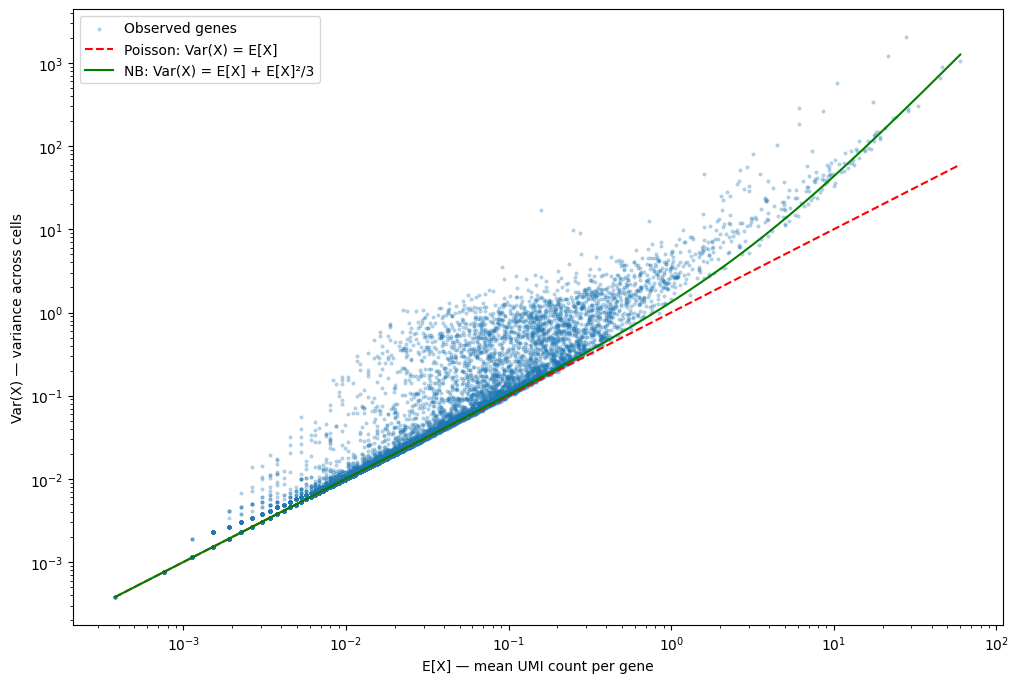

In [21]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [22]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [23]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: 'counts'

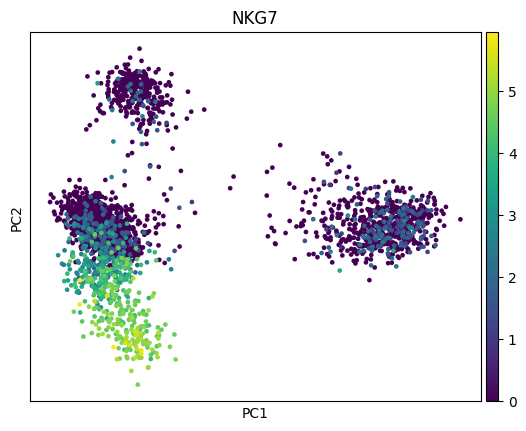

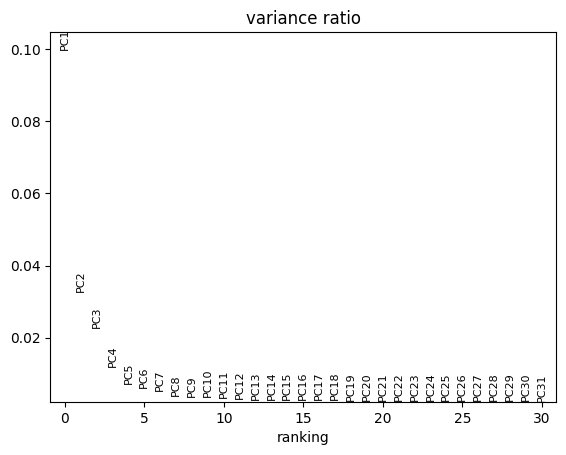

In [24]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [25]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'

## Подумайте

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

### **Ответы на подумать**

**1. Что находится в слоях AnnData?**

В `adata.layers["counts"]` хранятся исходные UMI counts после фильтрации, а в `adata.X` — нормализованные и логарифмированные значения экспрессии. В `adata.obsm["X_pca"]` находятся координаты клеток после PCA, а в `adata.varm["PCs"]` — нагрузки генов на главные компоненты. Последние два поля не являются слоями `layers`.

**2. По каким ещё генам можно проводить QC?**

Помимо митохондриальных, можно использовать рибосомные (`RPL`, `RPS`), гемоглобиновые (`HBA1`, `HBA2`, `HBB`) и стрессовые гены (`FOS`, `JUN`, `HSPA1A`). Их повышенная экспрессия может указывать на стресс, загрязнение образца или особенности клеточного состава.

**3. Как лучше проводить QC: по названиям генов или с помощью GTF/GFF?**

Использование GTF/GFF надёжнее, поскольку позволяет определять гены по аннотации и расположению в геноме. Поиск по названиям проще, но может пропускать нужные гены или ошибочно включать другие.

**4. Сколько генов на митохондриальной хромосоме? Все ли начинаются с mt?**

В митохондриальном геноме человека 37 генов: 13 белок-кодирующих, 22 тРНК и 2 рРНК. В нашем датасете обнаружено 13 генов с префиксом `MT-`. Не все гены, связанные с митохондриями, имеют этот префикс, поскольку многие кодируются в ядре.

**5. Как обозначаются митохондриальные гены у других организмов?**

У человека обычно используется `MT-`, у мыши — `mt-`. У коров, собак и других приматов обозначения зависят от базы аннотаций: встречаются `MT-`, `ND1`, `COX1`, `CYTB` и другие. Поэтому надёжнее определять митохондриальные гены по аннотации, а не только по названию.

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили.

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [26]:
adata_qc = sc.read_10x_mtx(
    "data/filtered_gene_bc_matrices/hg19/"
)

# Отмечаем группы генов
adata_qc.var["mt"] = adata_qc.var_names.str.startswith("MT-")
adata_qc.var["ribo"] = adata_qc.var_names.str.startswith(("RPS", "RPL"))
adata_qc.var["hb"] = adata_qc.var_names.str.match(r"^HB[ABDEG]")

# Проверяем количество генов в каждой группе
print("Клеток:", adata_qc.n_obs)
print("Митохондриальных генов:", adata_qc.var["mt"].sum())
print("Рибосомальных генов:", adata_qc.var["ribo"].sum())
print("Гемоглобиновых генов:", adata_qc.var["hb"].sum())

Клеток: 2700
Митохондриальных генов: 13
Рибосомальных генов: 106
Гемоглобиновых генов: 8


In [27]:
sc.pp.calculate_qc_metrics(
    adata_qc,
    qc_vars=["mt", "ribo", "hb"],
    percent_top=None,
    inplace=True
)

adata_qc.obs[
    [
        "n_genes_by_counts",
        "total_counts",
        "pct_counts_mt",
        "pct_counts_ribo",
        "pct_counts_hb"
    ]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb
AAACATACAACCAC-1,781,2421.0,3.015283,43.659645,0.0
AAACATTGAGCTAC-1,1352,4903.0,3.793596,42.402611,0.0
AAACATTGATCAGC-1,1131,3149.0,0.889171,31.660847,0.0
AAACCGTGCTTCCG-1,960,2639.0,1.743085,24.251610,0.0
AAACCGTGTATGCG-1,522,981.0,1.223242,14.882773,0.0


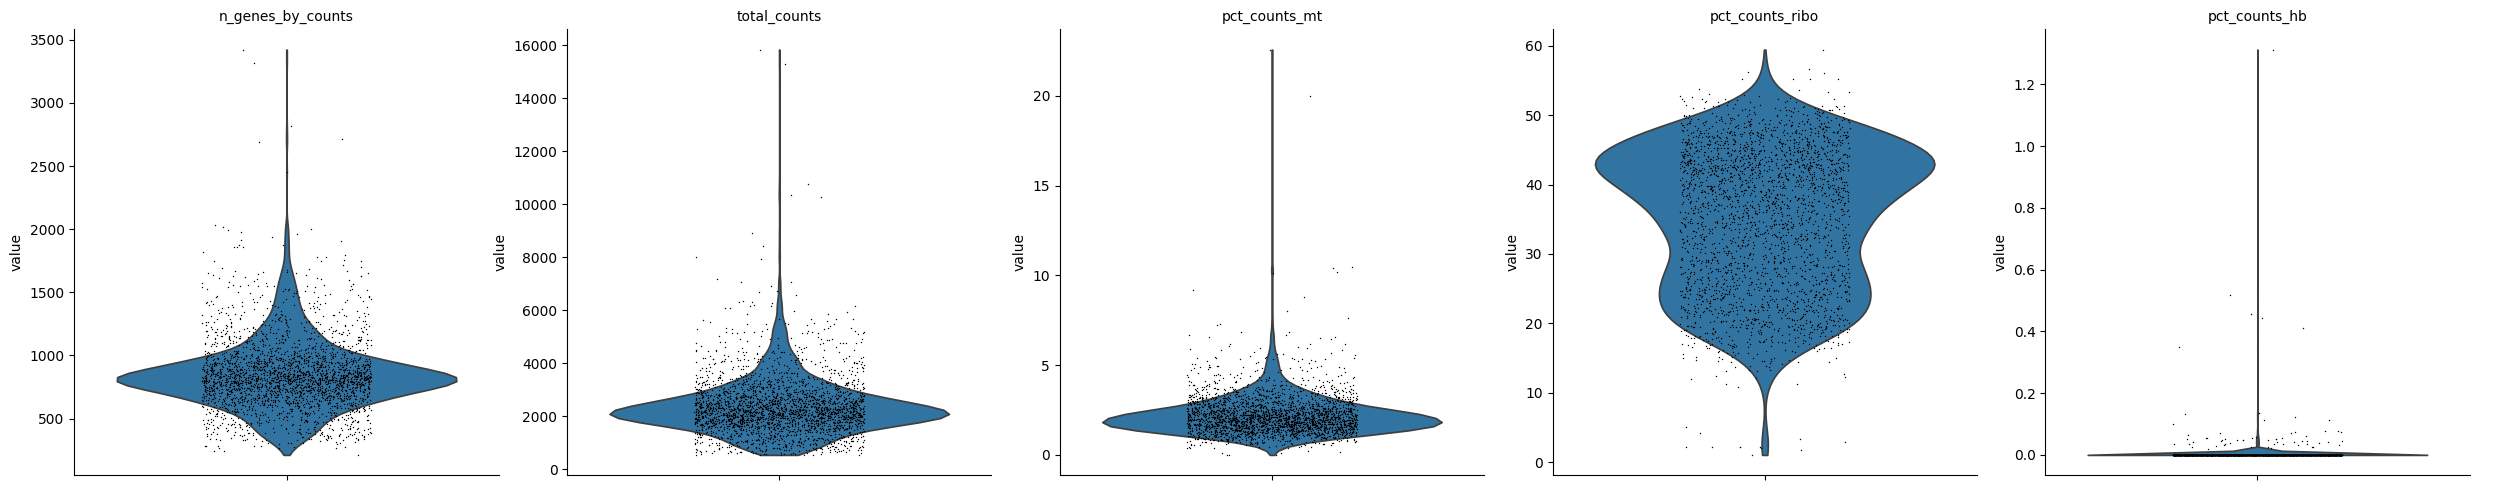

In [28]:
qc_metrics = [
    "n_genes_by_counts",
    "total_counts",
    "pct_counts_mt",
    "pct_counts_ribo",
    "pct_counts_hb"
]

sc.pl.violin(
    adata_qc,
    keys=qc_metrics,
    multi_panel=True,
    jitter=0.2
)

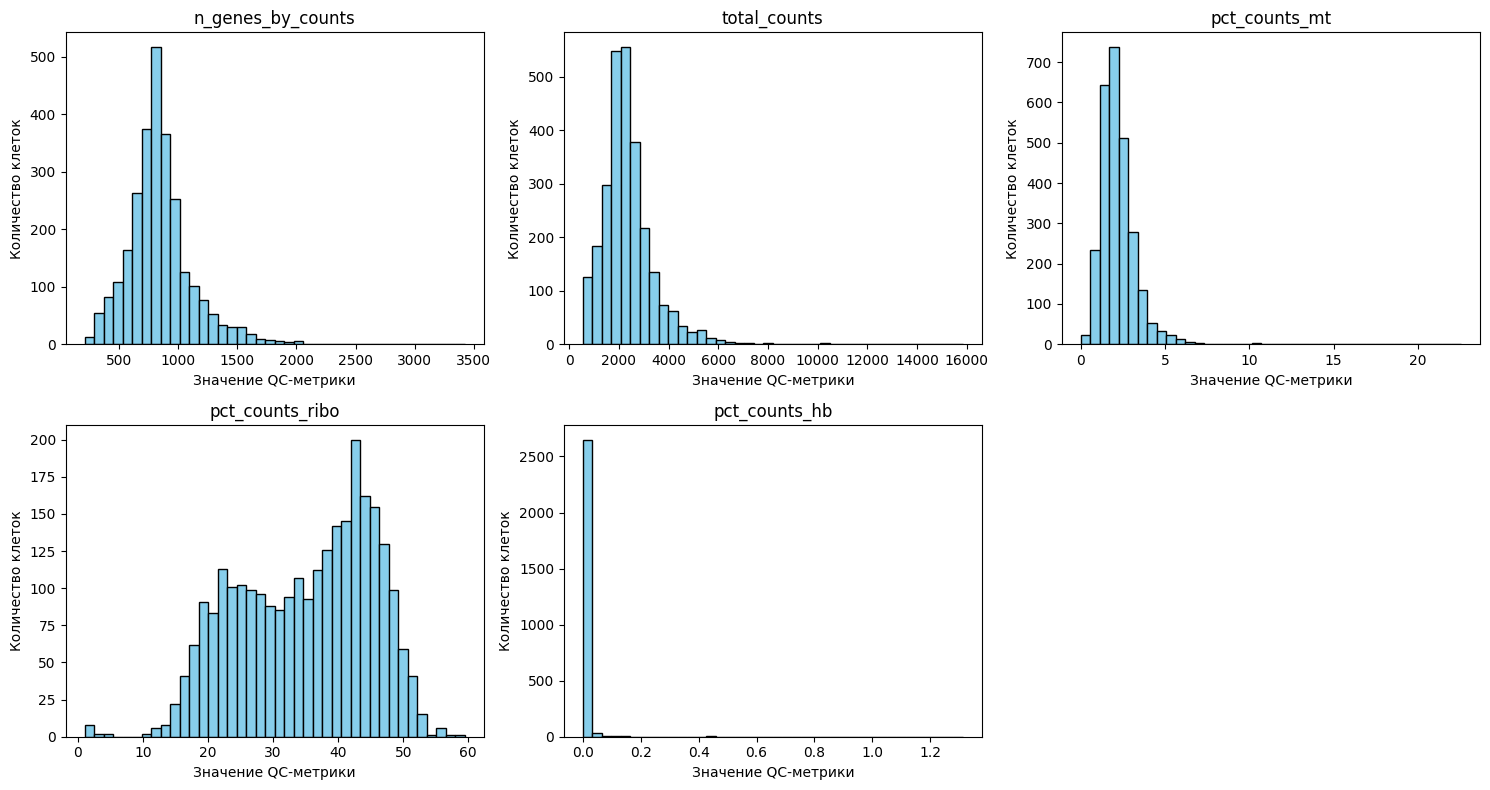

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, metric in zip(axes.flat, qc_metrics):
    ax.hist(adata_qc.obs[metric], bins=40,
            color="skyblue", edgecolor="black")
    ax.set_title(metric)
    ax.set_xlabel("Значение QC-метрики")
    ax.set_ylabel("Количество клеток")

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

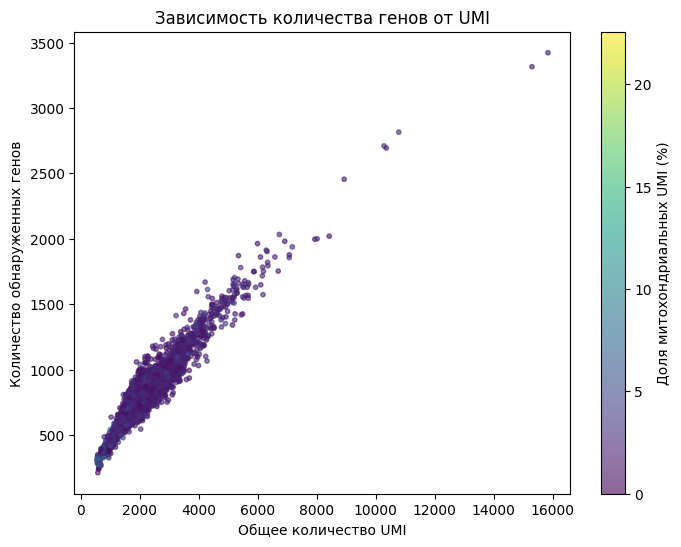

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    adata_qc.obs["total_counts"],
    adata_qc.obs["n_genes_by_counts"],
    c=adata_qc.obs["pct_counts_mt"],
    cmap="viridis",
    s=10,
    alpha=0.6
)

plt.xlabel("Общее количество UMI")
plt.ylabel("Количество обнаруженных генов")
plt.title("Зависимость количества генов от UMI")

plt.colorbar(label="Доля митохондриальных UMI (%)")

plt.show()

### Выводы по заданию 1

В ходе QC были проанализированы 2700 клеток PBMC 3k. Помимо стандартных метрик, рассчитаны доли рибосомальных и гемоглобиновых UMI.

**1. Какие клетки выглядят подозрительными?**

Клетки с очень низким количеством генов и UMI могут быть низкокачественными, а с аномально высокими значениями — потенциальными дублетами. Также подозрительны клетки с повышенной долей митохондриальных транскриптов.

**2. Какие метрики могут свидетельствовать о низком качестве клетки?**

Низкие `n_genes_by_counts` и `total_counts` могут указывать на недостаточное количество захваченной РНК. Высокая `pct_counts_mt` может свидетельствовать о повреждении клеток. На графике наблюдается положительная зависимость между количеством UMI и обнаруженных генов.

**3. Почему высокая доля определённой группы генов не всегда означает плохое качество?**

Экспрессия зависит от типа и физиологического состояния клетки. Например, высокая доля рибосомальных транскриптов может отражать особенности белкового синтеза, а гемоглобиновых — присутствие эритроидных клеток или их РНК.

**-->** QC позволяет выявлять потенциально низкокачественные клетки, однако интерпретировать показатели необходимо в совокупности, учитывая биологические особенности исследуемых клеток.

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`.

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


In [31]:
# Копируем данные после QC и нормализации
adata_hvg = adata.copy()

# Сохраняем список HVG метода seurat_v3
hvg_v3 = set(
    adata_hvg.var_names[adata_hvg.var["highly_variable"]]
)

# Отбираем HVG методом seurat
sc.pp.highly_variable_genes(
    adata_hvg,
    flavor="seurat",
    n_top_genes=2000
)

# Сохраняем второй список
hvg_seurat = set(
    adata_hvg.var_names[adata_hvg.var["highly_variable"]]
)

print("HVG seurat_v3:", len(hvg_v3))
print("HVG seurat:", len(hvg_seurat))
print("Общих генов:", len(hvg_v3 & hvg_seurat))

HVG seurat_v3: 2000
HVG seurat: 2000
Общих генов: 1505


In [32]:
adata_exp = adata.copy()

sc.experimental.pp.highly_variable_genes(
    adata_exp,
    flavor="pearson_residuals",
    n_top_genes=2000,
    layer="counts"
)

hvg_exp = set(
    adata_exp.var_names[adata_exp.var["highly_variable"]]
)

print("HVG experimental:", len(hvg_exp))
print("Общие с seurat_v3:", len(hvg_exp & hvg_v3))
print("Общие с seurat:", len(hvg_exp & hvg_seurat))
print("Общие для всех трёх:", len(hvg_exp & hvg_v3 & hvg_seurat))

HVG experimental: 2000
Общие с seurat_v3: 1402
Общие с seurat: 1291
Общие для всех трёх: 1145


In [33]:
# Создаём копии данных
adata_v3_pca = adata.copy()
adata_seurat_pca = adata.copy()
adata_exp_pca = adata.copy()

# Устанавливаем соответствующие HVG
adata_v3_pca.var["highly_variable"] = adata_v3_pca.var_names.isin(hvg_v3)
adata_seurat_pca.var["highly_variable"] = adata_seurat_pca.var_names.isin(hvg_seurat)
adata_exp_pca.var["highly_variable"] = adata_exp_pca.var_names.isin(hvg_exp)

# Рассчитываем PCA
for data in [adata_v3_pca, adata_seurat_pca, adata_exp_pca]:
    sc.tl.pca(data, mask_var="highly_variable", n_comps=30)

print("PCA рассчитан для всех трёх методов!")

PCA рассчитан для всех трёх методов!



PCA: Seurat v3


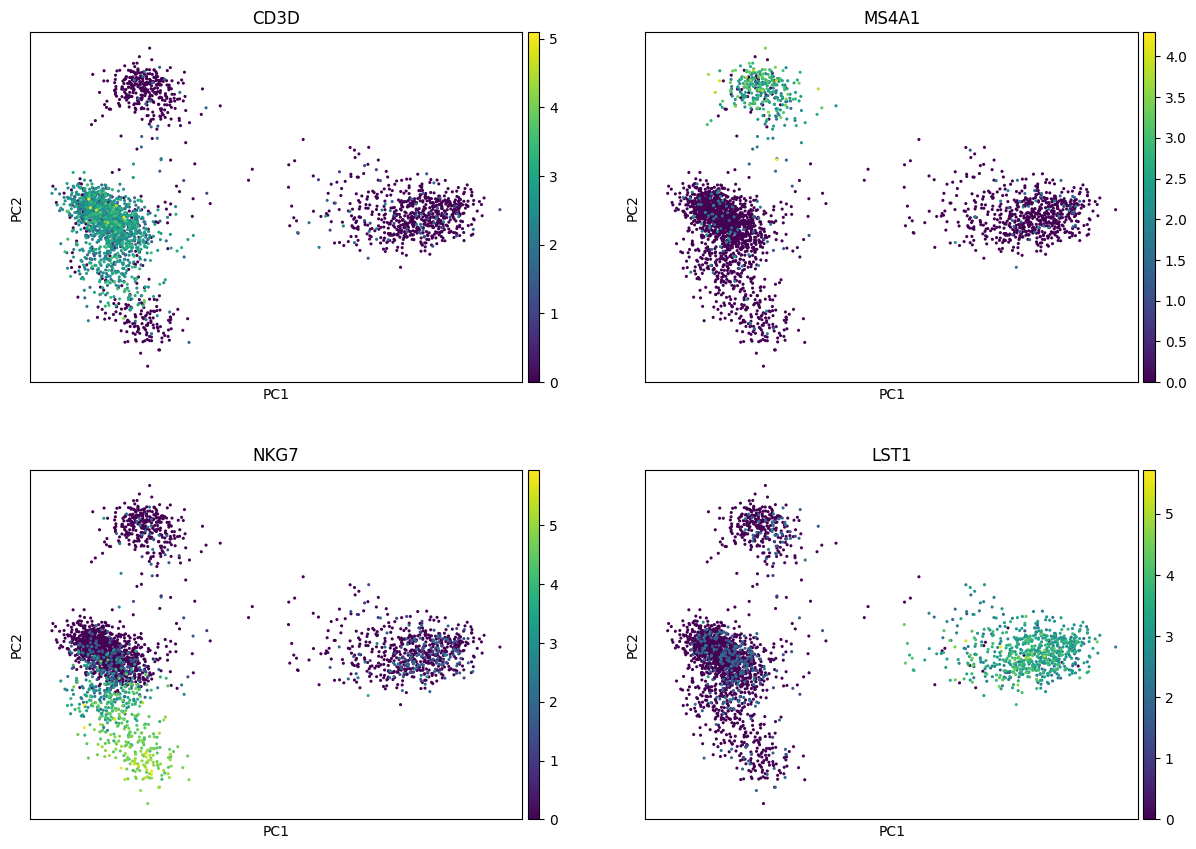


PCA: Seurat


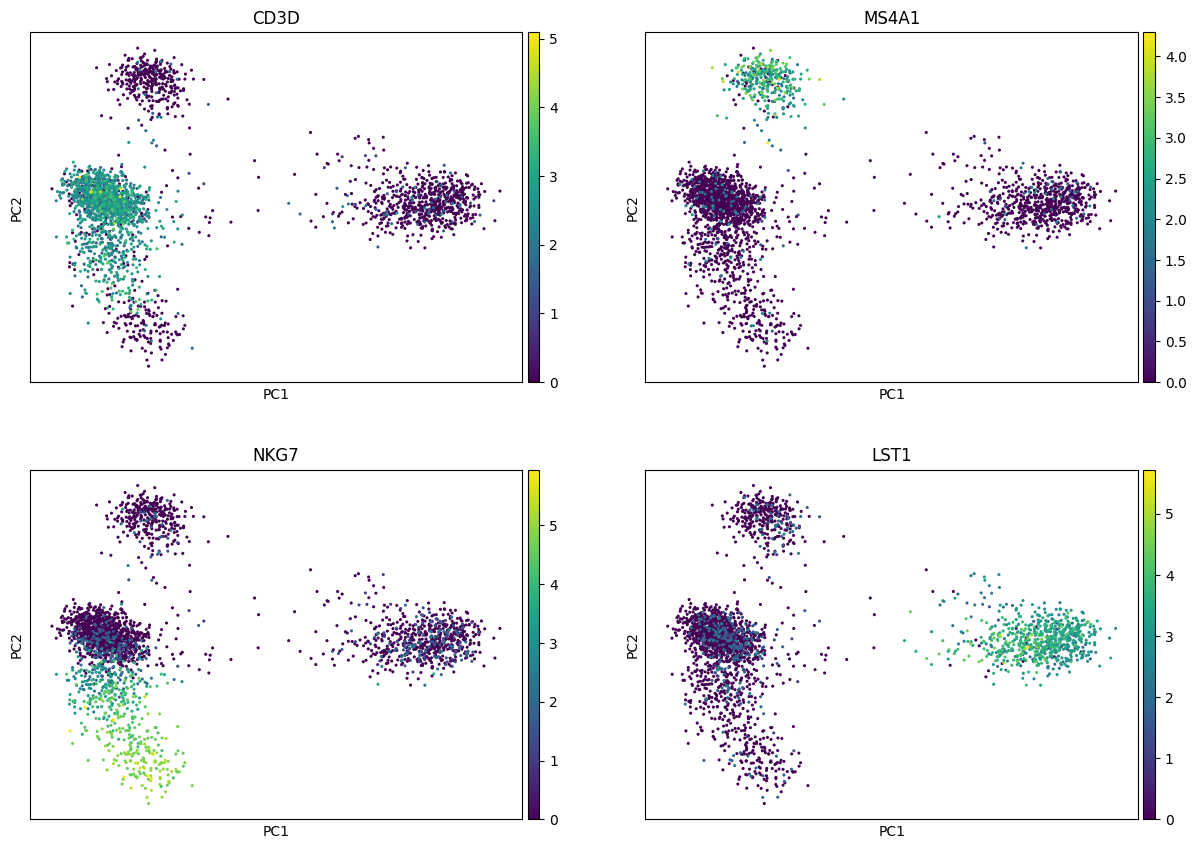


PCA: Pearson residuals


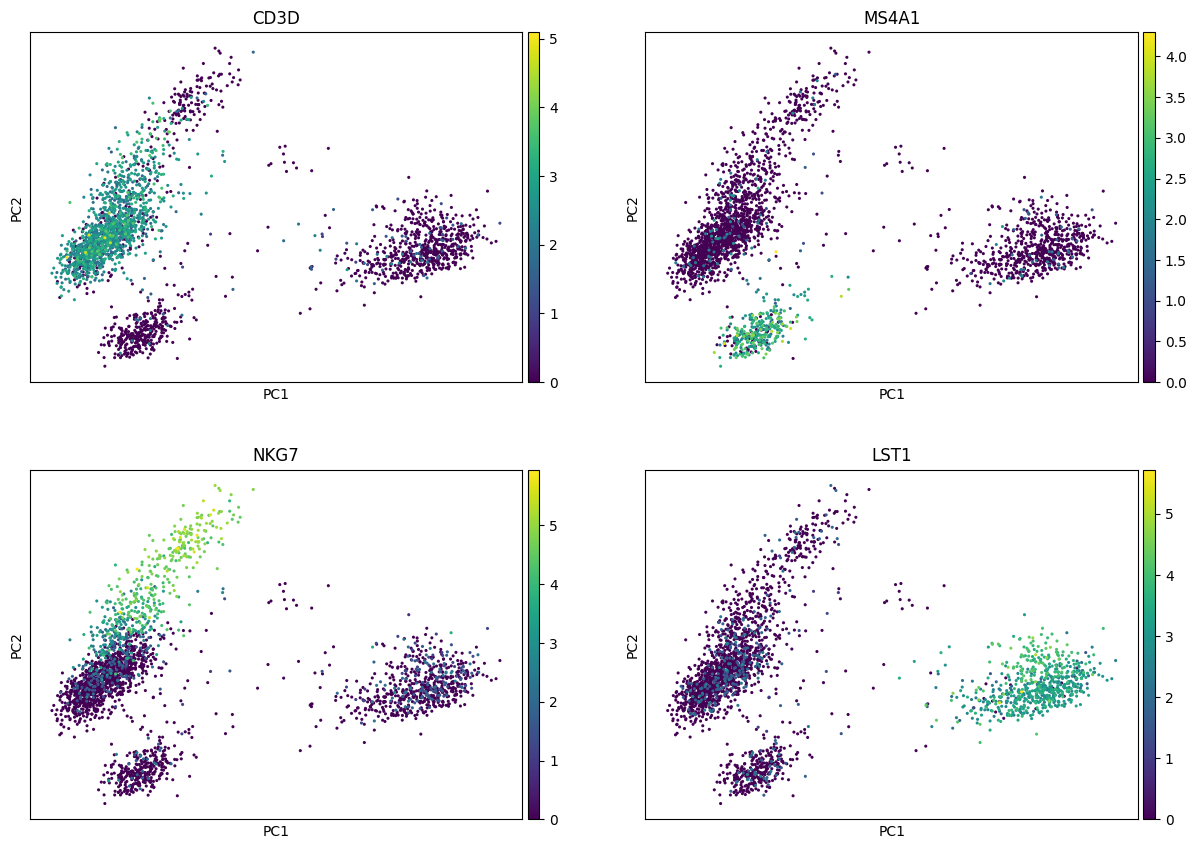

In [34]:
markers = ["CD3D", "MS4A1", "NKG7", "LST1"]

datasets = {
    "Seurat v3": adata_v3_pca,
    "Seurat": adata_seurat_pca,
    "Pearson residuals": adata_exp_pca
}

for method, data in datasets.items():
    print(f"\nPCA: {method}")

    sc.pl.pca(
        data,
        color=markers,
        ncols=2,
        size=20,
        show=True
    )

### Выводы по заданию 2

**1. Насколько отличаются расположения клеток?**

Результаты PCA для `seurat_v3` и `seurat` очень похожи. Метод `pearson_residuals` заметнее меняет расположение и форму клеточных групп, особенно популяции с высокой экспрессией NKG7.

**2. Сохраняются ли группы клеток с характерной экспрессией маркеров?**

Да, при всех трёх методах сохраняются основные группы: T-лимфоциты (`CD3D`), B-лимфоциты (`MS4A1`), цитотоксические лимфоциты (`NKG7`) и моноциты (`LST1`). Таким образом, основные биологические различия остаются различимыми.

**3. Сколько генов одновременно попало в оба набора HVG?**

- `seurat_v3` и `seurat` — 1505 генов.
- `seurat_v3` и `pearson_residuals` — 1402 гена.
- `seurat` и `pearson_residuals` — 1291 ген.
- Общих для всех трёх методов — 1145 генов.

**-->** способ отбора HVG влияет на расположение клеток в PCA, однако основные клеточные популяции сохраняются при всех трёх методах.

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


In [35]:
# Создаём две копии одинаковых данных
adata_all = adata.copy()
adata_hvg_only = adata.copy()

# PCA по всем генам
sc.tl.pca(
    adata_all,
    mask_var=None,
    n_comps=30
)

# PCA по 2000 HVG
sc.tl.pca(
    adata_hvg_only,
    mask_var="highly_variable",
    n_comps=30
)

print("PCA по всем генам:", adata_all.obsm["X_pca"].shape)
print("PCA по HVG:", adata_hvg_only.obsm["X_pca"].shape)

PCA по всем генам: (2638, 30)
PCA по HVG: (2638, 30)


PCA по всем генам


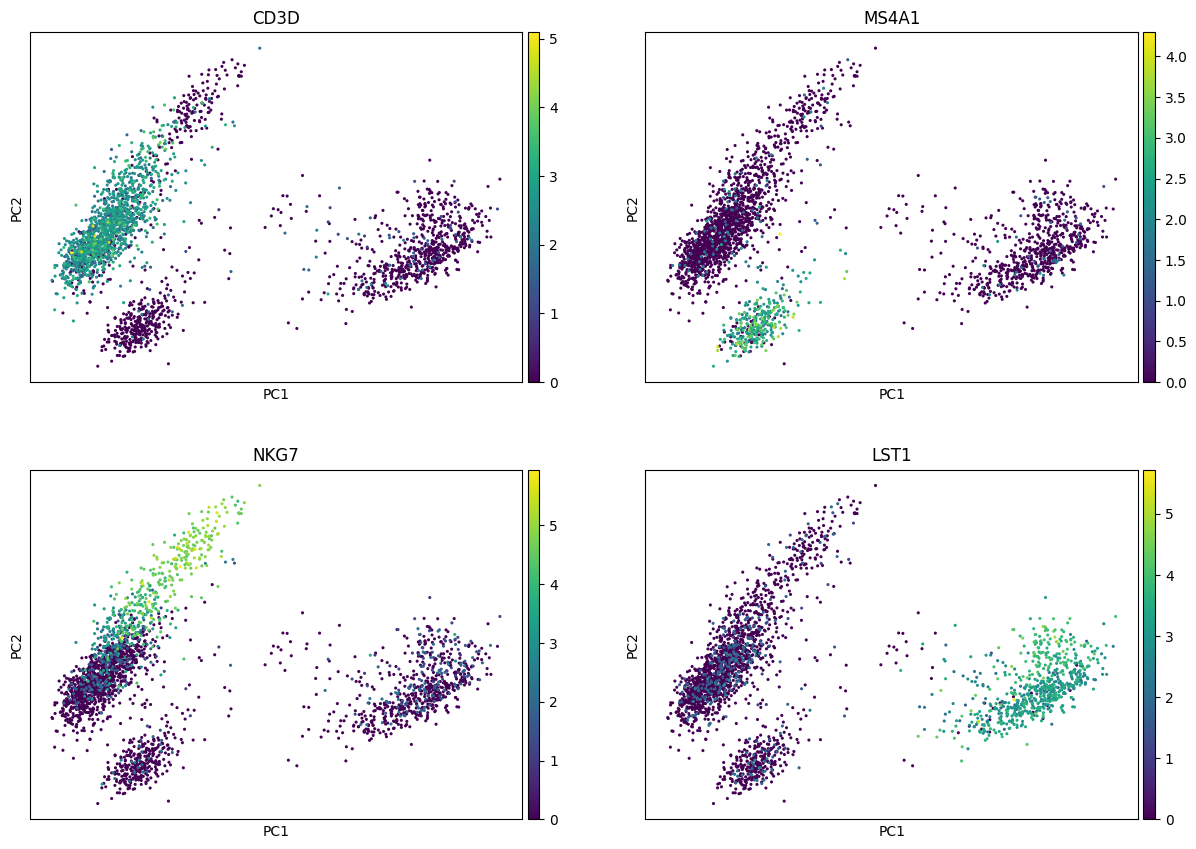

PCA по HVG


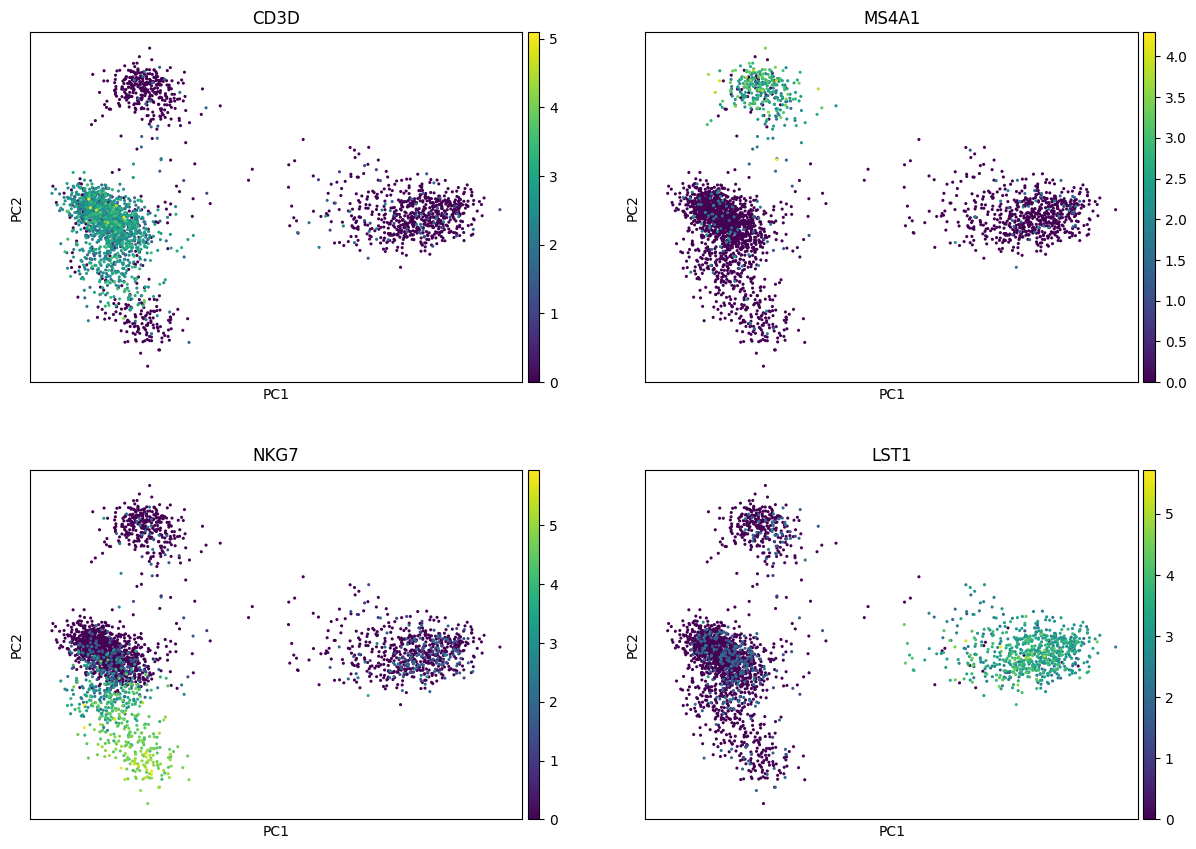

In [36]:
markers = ["CD3D", "MS4A1", "NKG7", "LST1"]

for name, data in {
    "PCA по всем генам": adata_all,
    "PCA по HVG": adata_hvg_only
}.items():

    print(name)

    sc.pl.pca(
        data,
        color=markers,
        ncols=2,
        size=20
    )

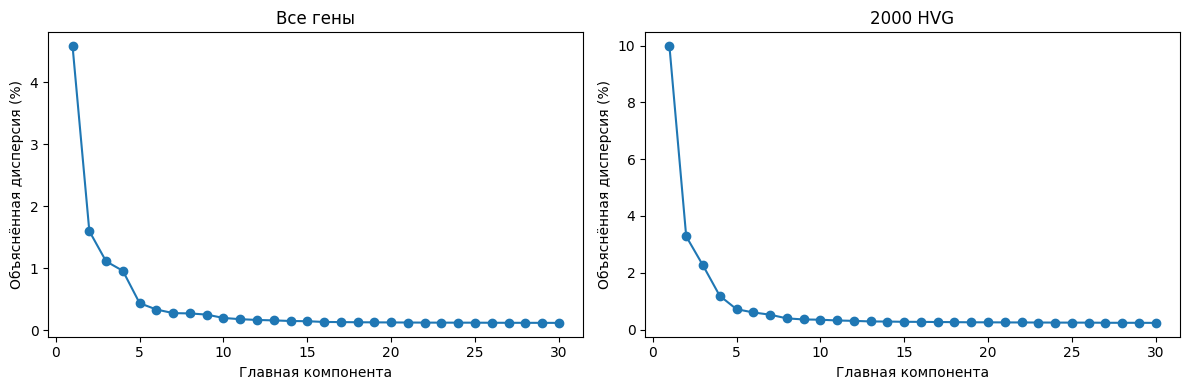

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, data) in zip(
    axes,
    {
        "Все гены": adata_all,
        "2000 HVG": adata_hvg_only
    }.items()
):
    variance = data.uns["pca"]["variance_ratio"]

    ax.plot(range(1, len(variance) + 1), variance * 100, marker="o")
    ax.set_title(name)
    ax.set_xlabel("Главная компонента")
    ax.set_ylabel("Объяснённая дисперсия (%)")

plt.tight_layout()
plt.show()

### Выводы по заданию 3

**1. Как изменилось расположение клеток?**

При использовании всех генов основные клеточные популяции сохраняются, но их расположение в PCA изменяется. При отборе 2000 HVG некоторые группы выглядят более компактными и отчётливо разделёнными.

**2. Какие компоненты объясняют больше дисперсии?**

В обоих вариантах наибольшую долю дисперсии объясняет PC1. При использовании всех генов её вклад составляет около 4,6%, а при использовании HVG — около 10%. PC2 объясняет примерно 1,6% и 3,3% соответственно.

**3. Почему использование всех генов не обязательно делает PCA информативнее?**

Многие гены обладают низкой вариабельностью и слабо отражают различия между клеточными популяциями. Их включение может добавлять технический шум. Отбор HVG позволяет сосредоточиться на генах, наиболее информативных для выявления клеточной неоднородности.

**-->** использование HVG помогает выделить основные биологические различия между клетками, хотя клеточные популяции остаются различимыми и при PCA по всем генам.

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


In [38]:
import pandas as pd
import numpy as np

# Исходные UMI counts после QC
counts = adata.layers["counts"]

# Среднее количество UMI на клетку
mean_umi = np.asarray(counts.mean(axis=0)).ravel()

# Дисперсия исходных UMI counts
mean_sq = np.asarray(counts.power(2).mean(axis=0)).ravel()
variance_umi = mean_sq - mean_umi**2

# Создаём таблицу генов
genes_df = pd.DataFrame({
    "gene": adata.var_names,
    "mean_UMI": mean_umi,
    "variance": variance_umi,
    "HVG": adata.var["highly_variable"].values
})

# 50 наиболее экспрессируемых HVG
top50_hvg = (
    genes_df[genes_df["HVG"]]
    .sort_values("mean_UMI", ascending=False)
    .head(50)
)

# 50 наиболее экспрессируемых не-HVG
top50_non_hvg = (
    genes_df[~genes_df["HVG"]]
    .sort_values("mean_UMI", ascending=False)
    .head(50)
)

print("Топ-50 HVG:")
display(top50_hvg.head(10))

print("Топ-50 не-HVG:")
display(top50_non_hvg.head(10))

Топ-50 HVG:


,gene,mean_UMI,variance,HVG
7854,MALAT1,60.036732,1066.570312,True
5540,TMSB4X,46.140289,883.349854,True
9781,B2M,45.289223,659.148682,True
12943,FTL,27.999430,2041.886475,True
7754,FTH1,21.535463,1224.520508,True
4926,ACTB,17.458569,334.396576,True
8681,LYZ,10.408192,575.139343,True
4025,CD74,8.579643,261.793152,True
912,S100A4,7.343126,86.244446,True
13699,MT-CO2,6.888643,56.957253,True


Топ-50 не-HVG:


,gene,mean_UMI,variance,HVG
5915,RPL10,33.017464,307.453003,False
10709,RPL13,28.774101,280.543518,False
12956,RPL13A,28.644434,264.611633,False
10129,RPS2,24.092089,222.750671,False
6461,RPS6,23.292944,217.958923,False
4436,RPS18,20.609489,166.668060,False
227,RPL11,19.285789,128.377533,False
2390,RPL32,19.239534,122.027008,False
8004,RPS3,19.013590,146.748871,False
11118,RPL19,18.272491,149.700043,False


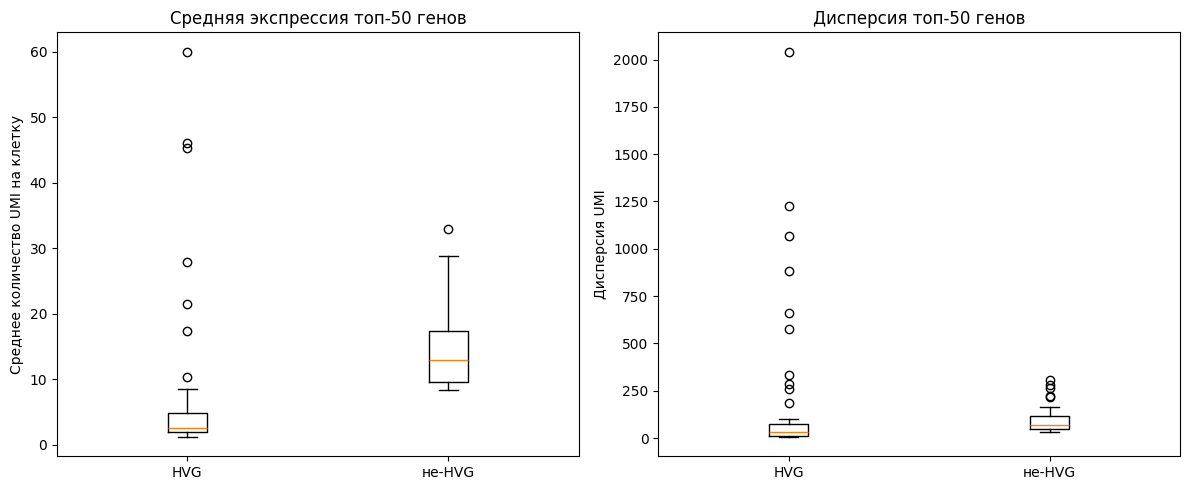

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(
    [top50_hvg["mean_UMI"], top50_non_hvg["mean_UMI"]],
    tick_labels=["HVG", "не-HVG"]
)
axes[0].set_title("Средняя экспрессия топ-50 генов")
axes[0].set_ylabel("Среднее количество UMI на клетку")

axes[1].boxplot(
    [top50_hvg["variance"], top50_non_hvg["variance"]],
    tick_labels=["HVG", "не-HVG"]
)
axes[1].set_title("Дисперсия топ-50 генов")
axes[1].set_ylabel("Дисперсия UMI")

plt.tight_layout()
plt.show()

### Выводы по заданию 4

**1. Обязательно ли HVG являются наиболее экспрессируемыми генами?**

Нет. Среди топ-50 не-HVG средняя экспрессия в целом выше, чем среди топ-50 HVG. Высокая экспрессия не обязательно сопровождается высокой вариабельностью между клетками.

**2. Почему высокоэкспрессируемый ген может не попасть в HVG?**

Если ген активно экспрессируется во многих клетках примерно на одном уровне, он может иметь недостаточную вариабельность относительно своей средней экспрессии. Метод `seurat_v3` учитывает эту зависимость, а не только абсолютную дисперсию.

**3. Какие функциональные группы генов встречаются среди наиболее экспрессируемых?**

Среди не-HVG преобладают гены рибосомальных белков (`RPL10`, `RPL13`, `RPS2`). Среди HVG встречаются гены иммунных функций (`B2M`, `CD74`, `LYZ`), цитоскелета (`ACTB`, `TMSB4X`) и обмена железа (`FTL`, `FTH1`).

**-->
** высокая средняя экспрессия не гарантирует попадания гена в HVG. Отбор HVG позволяет выделять гены, вариабельность которых особенно велика с учётом уровня экспрессии.

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

In [40]:
# Исходные данные без дополнительной QC-фильтрации
adata_raw = adata_qc.copy()

# Данные после QC-фильтрации
adata_filtered = adata.copy()

# Создаём четыре варианта
pca_noqc_all = adata_raw.copy()
pca_noqc_hvg = adata_raw.copy()

pca_qc_all = adata_filtered.copy()
pca_qc_hvg = adata_filtered.copy()

# Выбираем 2000 HVG для данных без QC
sc.pp.highly_variable_genes(
    pca_noqc_hvg,
    flavor="seurat_v3",
    n_top_genes=2000
)

# Для фильтрованных данных HVG уже рассчитаны
print("Без QC:", pca_noqc_all.n_obs, "клеток")
print("После QC:", pca_qc_all.n_obs, "клеток")

print(
    "HVG без QC:",
    pca_noqc_hvg.var["highly_variable"].sum()
)

print(
    "HVG после QC:",
    pca_qc_hvg.var["highly_variable"].sum()
)

Без QC: 2700 клеток
После QC: 2638 клеток
HVG без QC: 2000
HVG после QC: 2000


In [41]:
# Нормализуем данные без QC
for data in [pca_noqc_all, pca_noqc_hvg]:
    sc.pp.normalize_total(data, target_sum=1e4)
    sc.pp.log1p(data)

# Рассчитываем PCA для четырёх вариантов
datasets_pca5 = {
    "Без QC, все гены": (pca_noqc_all, None),
    "Без QC, HVG": (pca_noqc_hvg, "highly_variable"),
    "QC, все гены": (pca_qc_all, None),
    "QC, HVG": (pca_qc_hvg, "highly_variable")
}

for name, (data, mask) in datasets_pca5.items():
    sc.tl.pca(
        data,
        mask_var=mask,
        n_comps=30
    )
    print(name, data.obsm["X_pca"].shape)

Без QC, все гены (2700, 30)
Без QC, HVG (2700, 30)
QC, все гены (2638, 30)
QC, HVG (2638, 30)


In [42]:
# Добавляем долю рибосомальных UMI в данные после QC
for data in [pca_qc_all, pca_qc_hvg]:
    data.obs["pct_counts_ribo"] = (
        adata_qc.obs.loc[data.obs_names, "pct_counts_ribo"].values
    )

# Проверяем наличие метрики во всех четырёх объектах
for name, (data, mask) in datasets_pca5.items():
    print(name, ":", "pct_counts_ribo" in data.obs.columns)

Без QC, все гены : True
Без QC, HVG : True
QC, все гены : True
QC, HVG : True



PCA: Без QC, все гены


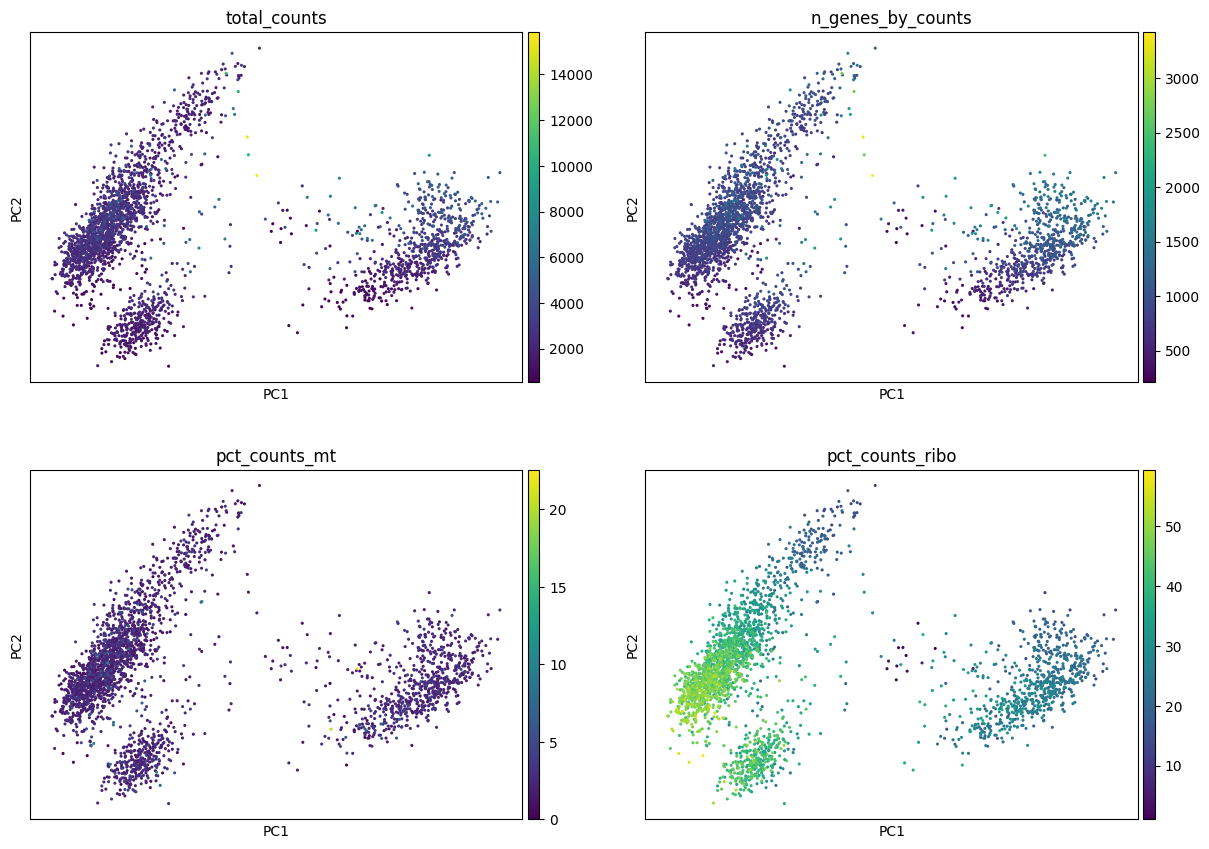


PCA: Без QC, HVG


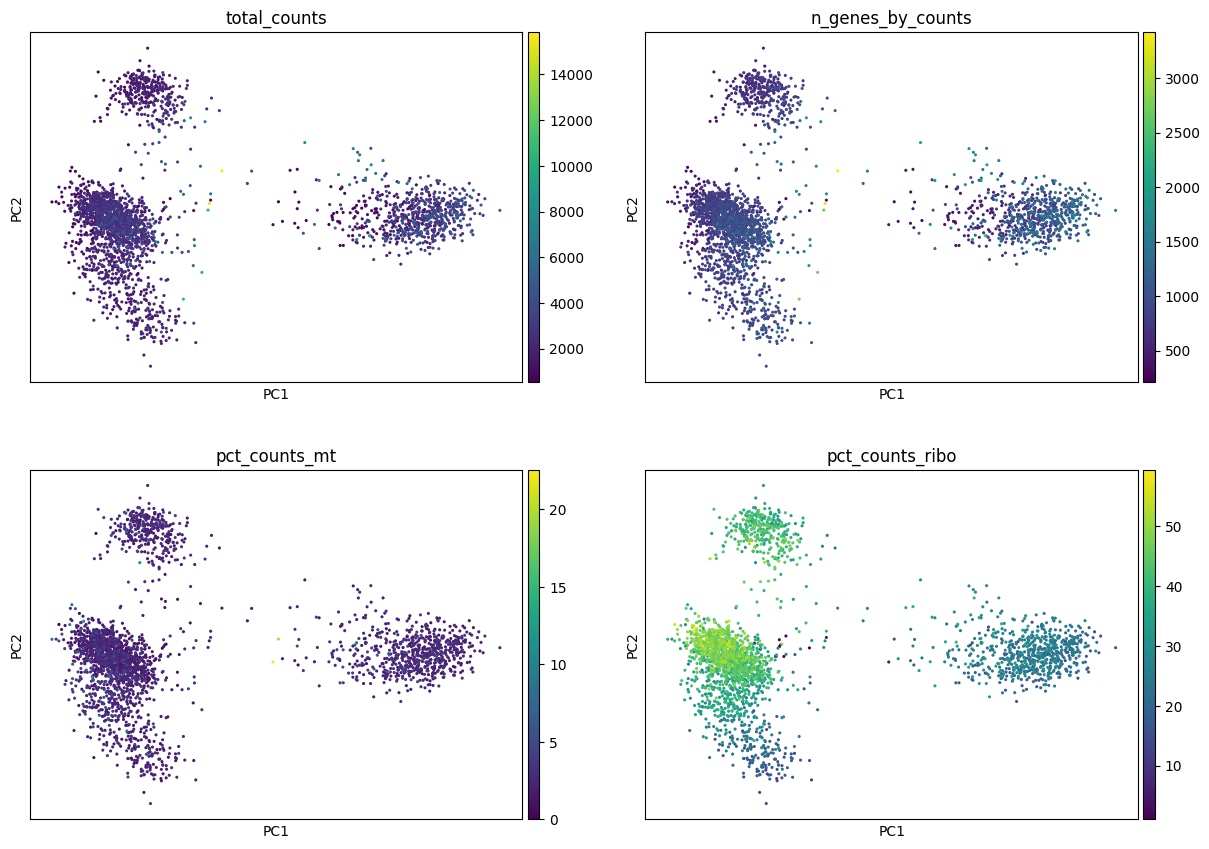


PCA: QC, все гены


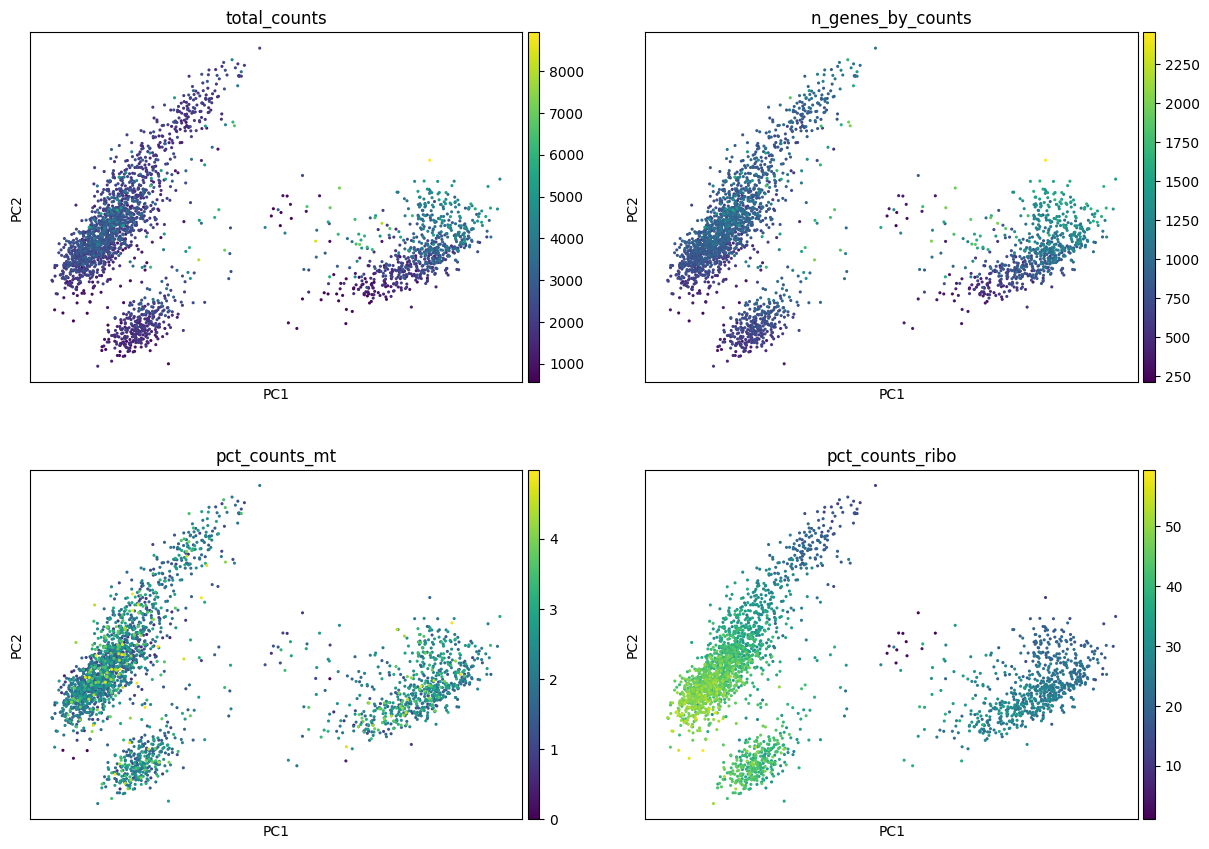


PCA: QC, HVG


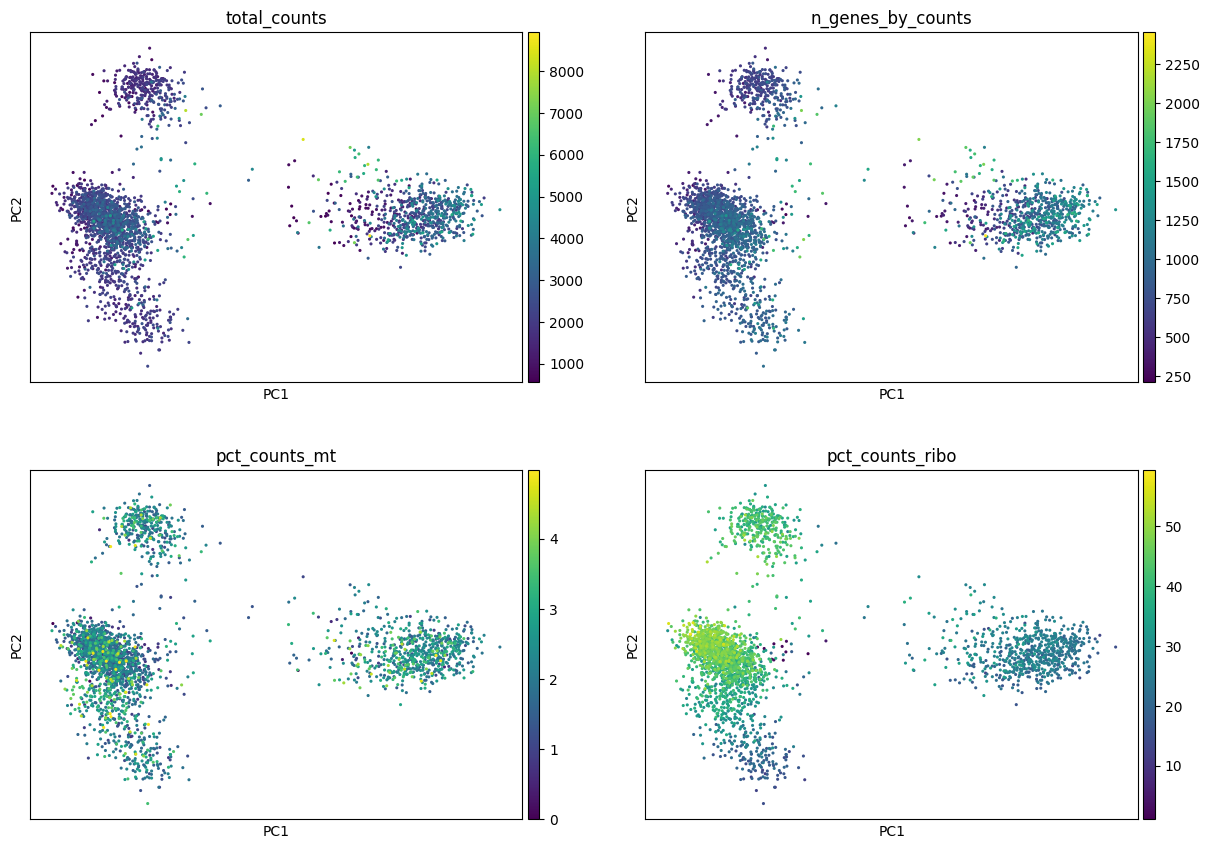

In [43]:
qc_markers = [
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_mt",
    "pct_counts_ribo"
]

for name, (data, mask) in datasets_pca5.items():
    print(f"\nPCA: {name}")

    sc.pl.pca(
        data,
        color=qc_markers,
        ncols=2,
        size=20
    )

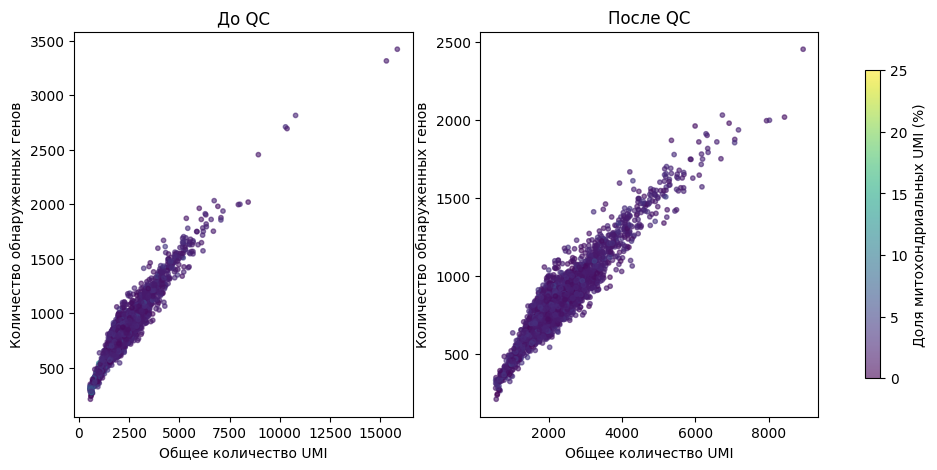

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, data) in zip(
    axes,
    {
        "До QC": pca_noqc_all,
        "После QC": pca_qc_all
    }.items()
):
    scatter = ax.scatter(
        data.obs["total_counts"],
        data.obs["n_genes_by_counts"],
        c=data.obs["pct_counts_mt"],
        cmap="viridis",
        vmin=0,
        vmax=25,
        s=10,
        alpha=0.6
    )

    ax.set_title(name)
    ax.set_xlabel("Общее количество UMI")
    ax.set_ylabel("Количество обнаруженных генов")

fig.colorbar(
    scatter,
    ax=axes,
    label="Доля митохондриальных UMI (%)",
    shrink=0.8
)

plt.show()

### Выводы по заданию 5

**1. Как QC-фильтрация влияет на PCA?**

После QC количество клеток сократилось с 2700 до 2638. Были удалены клетки с экстремальными значениями количества генов и повышенной долей митохондриальной РНК. Основные клеточные группы сохранились, но влияние потенциально низкокачественных клеток уменьшилось.

**2. Как влияет использование HVG?**

При использовании 2000 HVG некоторые клеточные группы становятся более компактными и отчётливо разделёнными. PCA по всем генам сильнее отражает вариации, связанные с количеством UMI и обнаруженных генов.

**3. Какие QC-метрики связаны с расположением клеток?**

Наиболее заметна связь с `total_counts`, `n_genes_by_counts` и `pct_counts_ribo`. Доля рибосомальных транскриптов различается между клеточными группами, что может отражать их биологические особенности. После фильтрации уменьшается диапазон значений `pct_counts_mt`.

**-->** QC-фильтрация устраняет потенциально некачественные клетки, а отбор HVG помогает выделить биологически информативные различия. При этом влияние технических факторов на PCA полностью не исчезает.


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

In [45]:
import pandas as pd

# Получаем нагрузки генов на главные компоненты
loadings = pd.DataFrame(
    adata.varm["PCs"][:, :2],
    index=adata.var_names,
    columns=["PC1", "PC2"]
)

# Отбираем по 10 генов с положительными
# и отрицательными нагрузками
top_genes = {}

for pc in ["PC1", "PC2"]:
    positive = loadings.nlargest(10, pc)
    negative = loadings.nsmallest(10, pc)

    top_genes[pc] = pd.concat([positive, negative])

    print(f"\n{pc}: 10 положительных loadings")
    display(positive[[pc]])

    print(f"{pc}: 10 отрицательных loadings")
    display(negative[[pc]])


PC1: 10 положительных loadings


,PC1
LYZ,0.220199
CST3,0.212370
S100A9,0.210871
TYROBP,0.199072
S100A8,0.170560
LGALS1,0.168186
AIF1,0.166196
LST1,0.165629
FCER1G,0.156248
FCN1,0.150878


PC1: 10 отрицательных loadings


,PC1
LTB,-0.112827
IL32,-0.106144
MALAT1,-0.067260
IL7R,-0.059417
CCL5,-0.051053
CD2,-0.045544
CTSW,-0.043735
STK17A,-0.037906
ACAP1,-0.036313
CD247,-0.036139



PC2: 10 положительных loadings


,PC2
HLA-DRA,0.267638
CD74,0.209744
HLA-DPB1,0.197693
HLA-DRB1,0.192726
CD79A,0.183641
HLA-DPA1,0.180487
HLA-DQA1,0.169166
HLA-DQB1,0.160824
CD79B,0.157985
HLA-DRB5,0.142120


PC2: 10 отрицательных loadings


,PC2
NKG7,-0.216003
S100A4,-0.180782
CCL5,-0.165345
IL32,-0.144603
GNLY,-0.134453
CTSW,-0.134233
GZMA,-0.134096
CST7,-0.131238
SRGN,-0.123198
ANXA1,-0.120073


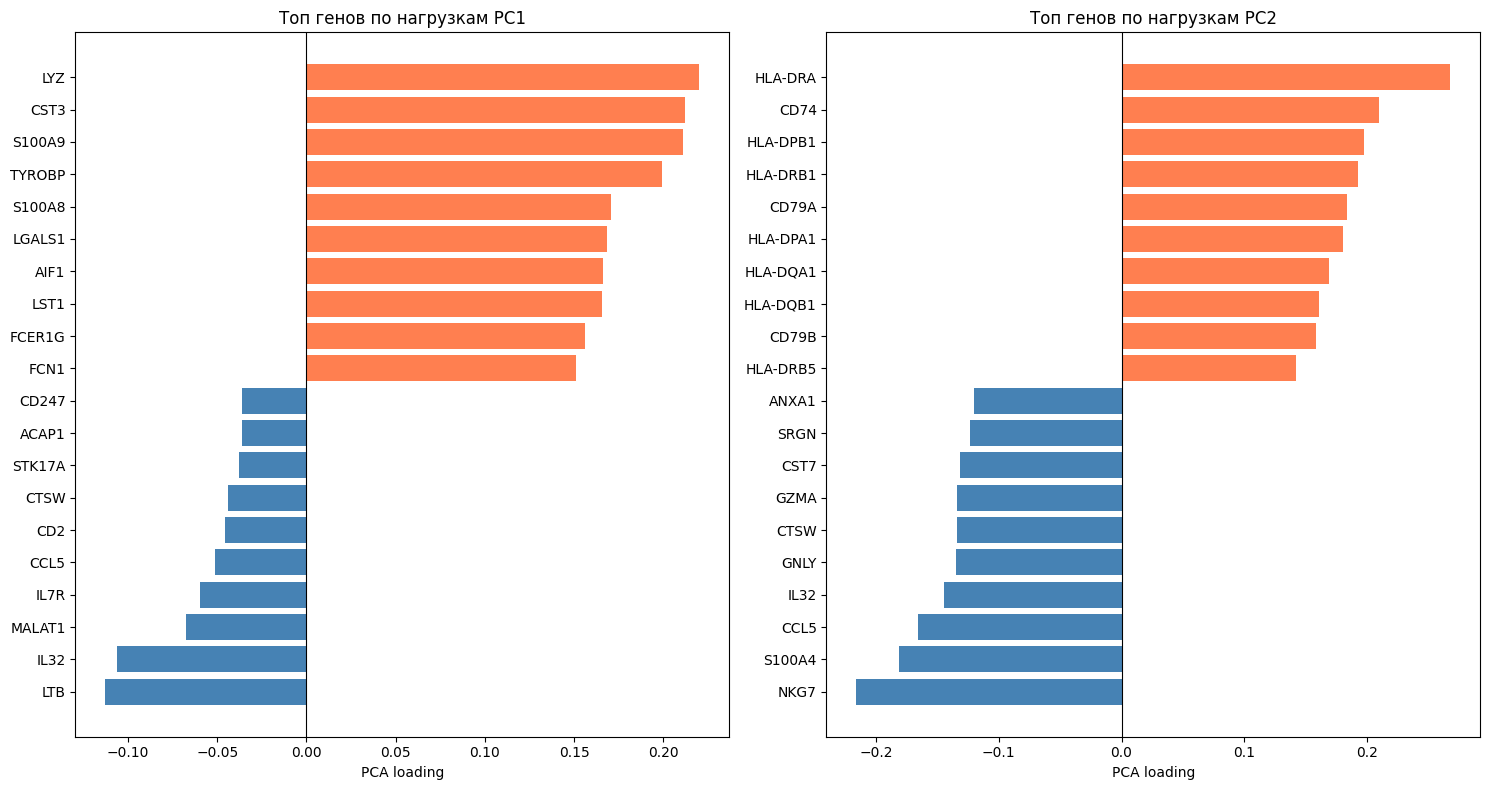

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

for ax, pc in zip(axes, ["PC1", "PC2"]):
    genes = top_genes[pc].sort_values(pc)

    colors = [
        "steelblue" if x < 0 else "coral"
        for x in genes[pc]
    ]

    ax.barh(genes.index, genes[pc], color=colors)
    ax.axvline(0, color="black", linewidth=0.8)

    ax.set_title(f"Топ генов по нагрузкам {pc}")
    ax.set_xlabel("PCA loading")

plt.tight_layout()
plt.show()

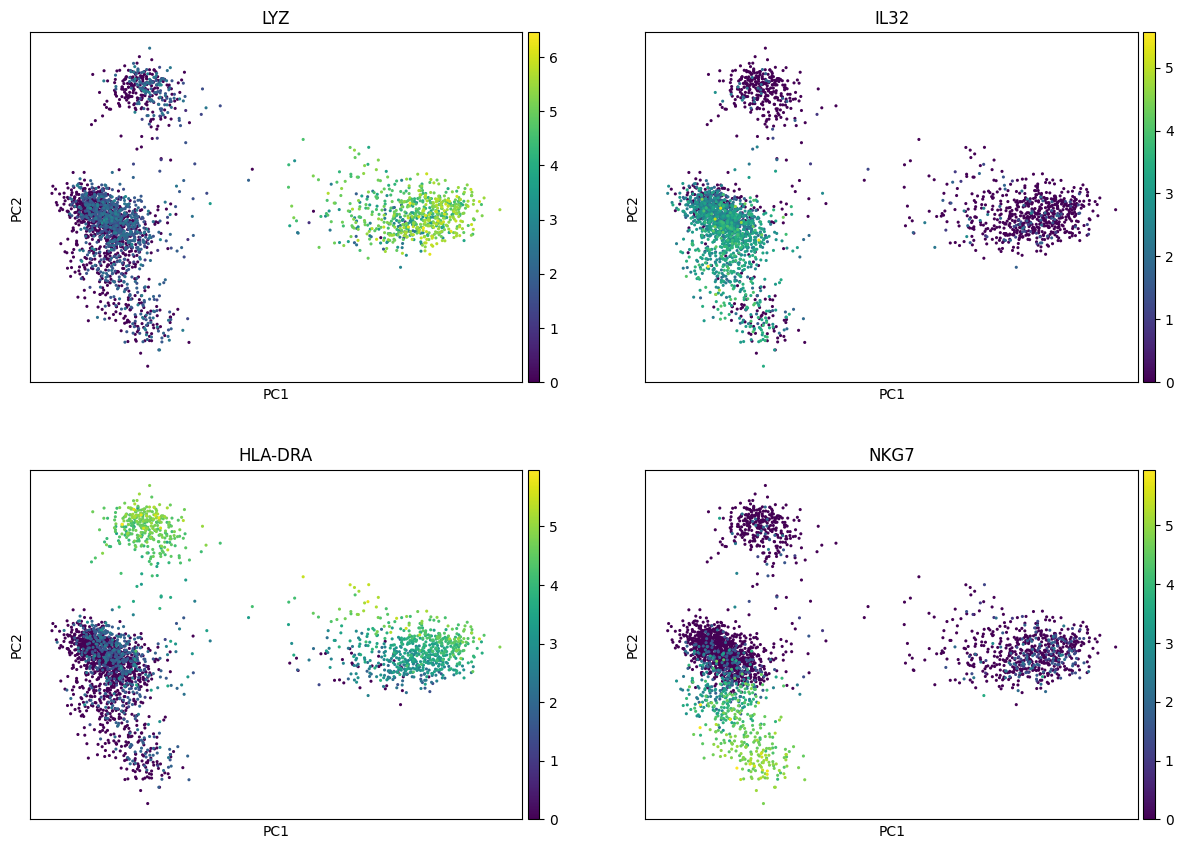

In [47]:
genes_to_plot = ["LYZ", "IL32", "HLA-DRA", "NKG7"]

sc.pl.pca(
    adata,
    color=genes_to_plot,
    ncols=2,
    size=20
)

### Выводы по заданию 6

**1. Какие гены сильнее всего влияют на PC1 и PC2?**

Для PC1 наибольшие положительные нагрузки имеют миелоидные маркеры `LYZ`, `CST3`, `S100A9`, а отрицательные — лимфоцитарные `LTB`, `IL32`, `IL7R`.

Для PC2 положительные нагрузки характерны для генов презентации антигенов (`HLA-DRA`, `CD74`, `CD79A`), а отрицательные — для цитотоксических маркеров (`NKG7`, `S100A4`, `CCL5`, `GNLY`).

**2. Какова биологическая интерпретация главных компонент?**

PC1 преимущественно разделяет миелоидные и лимфоидные клетки. PC2 отражает различия между клетками с выраженной экспрессией генов презентации антигенов и цитотоксическими лимфоцитами.

**3. Подтверждается ли интерпретация экспрессией генов?**

Да. `LYZ` наиболее активно экспрессируется в области положительных значений PC1, а `IL32` — отрицательных. `HLA-DRA` характерен для области положительных значений PC2, тогда как `NKG7` — отрицательных.

**-->** первые две главные компоненты отражают биологические различия между основными популяциями иммунных клеток PBMC 3k.

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток.

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

In [58]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt

# Берём 2000 HVG, выбранных ранее
hvg_mask = adata.var["highly_variable"].values

# Создаём четыре независимых объекта
datasets_pca7 = {}

names = [
    "Нормализация + log1p",
    "Только нормализация",
    "Без нормализации и log1p",
    "Нормализация + log1p + scale"
]

for name in names:
    data = adata[:, hvg_mask].copy()

    # Восстанавливаем исходные UMI counts
    data.X = data.layers["counts"].copy()

    # Удаляем старую информацию о логарифмировании
    data.uns.pop("log1p", None)

    datasets_pca7[name] = data

print("Подготовлено 4 варианта данных")
print("Клеток:", data.n_obs)
print("Генов:", data.n_vars)

Подготовлено 4 варианта данных
Клеток: 2638
Генов: 2000


In [59]:
# 1. Нормализация + log1p
data = datasets_pca7["Нормализация + log1p"]
sc.pp.normalize_total(data, target_sum=1e4)
sc.pp.log1p(data)

# 2. Только нормализация
data = datasets_pca7["Только нормализация"]
sc.pp.normalize_total(data, target_sum=1e4)

# 3. Без нормализации и log1p
# Оставляем исходные UMI counts

# 4. Нормализация + log1p + scale
data = datasets_pca7["Нормализация + log1p + scale"]
sc.pp.normalize_total(data, target_sum=1e4)
sc.pp.log1p(data)
sc.pp.scale(data, max_value=10)

print("Все варианты обработки готовы!")

Все варианты обработки готовы!


/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [60]:
# Используем одинаковые настройки PCA
for name, data in datasets_pca7.items():

    sc.tl.pca(
        data,
        n_comps=30,
        svd_solver="arpack"
    )

    print(name, data.obsm["X_pca"].shape)

Нормализация + log1p (2638, 30)
Только нормализация (2638, 30)
Без нормализации и log1p (2638, 30)
Нормализация + log1p + scale (2638, 30)



PCA: Нормализация + log1p


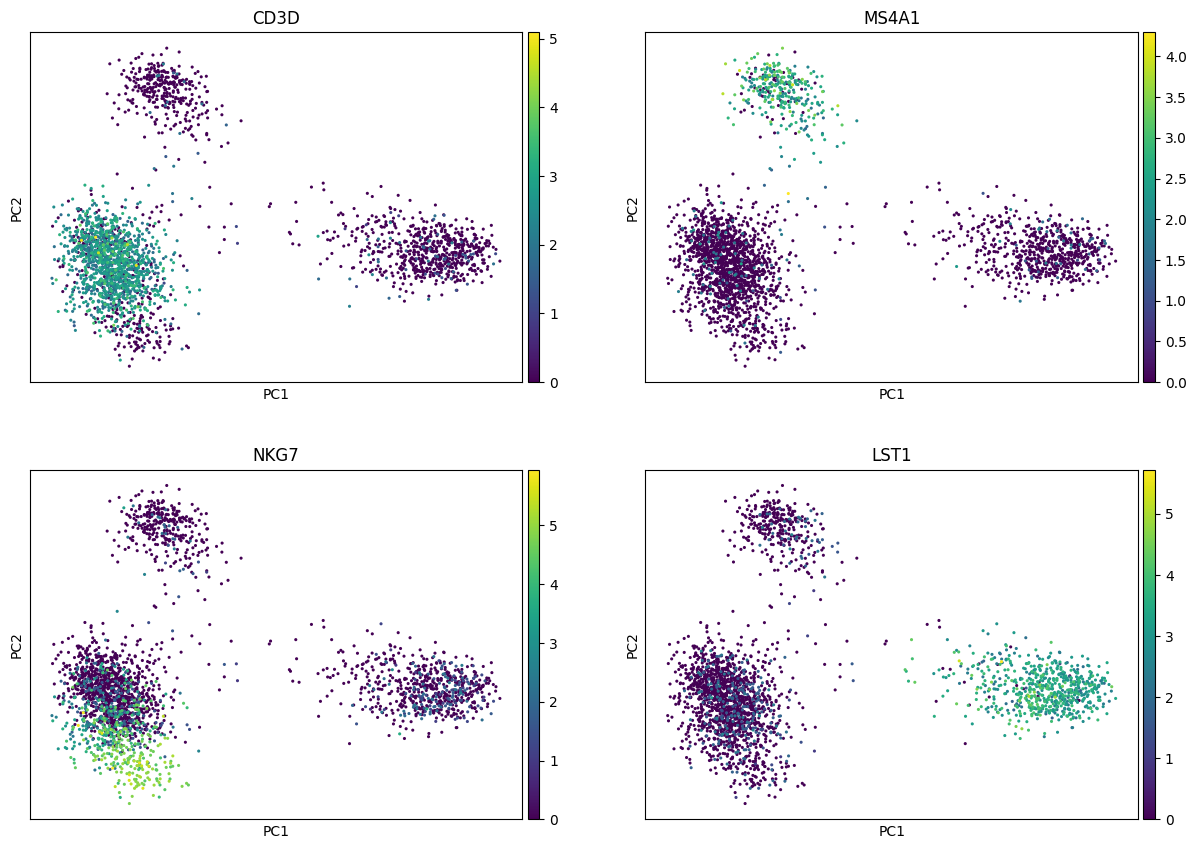


PCA: Только нормализация


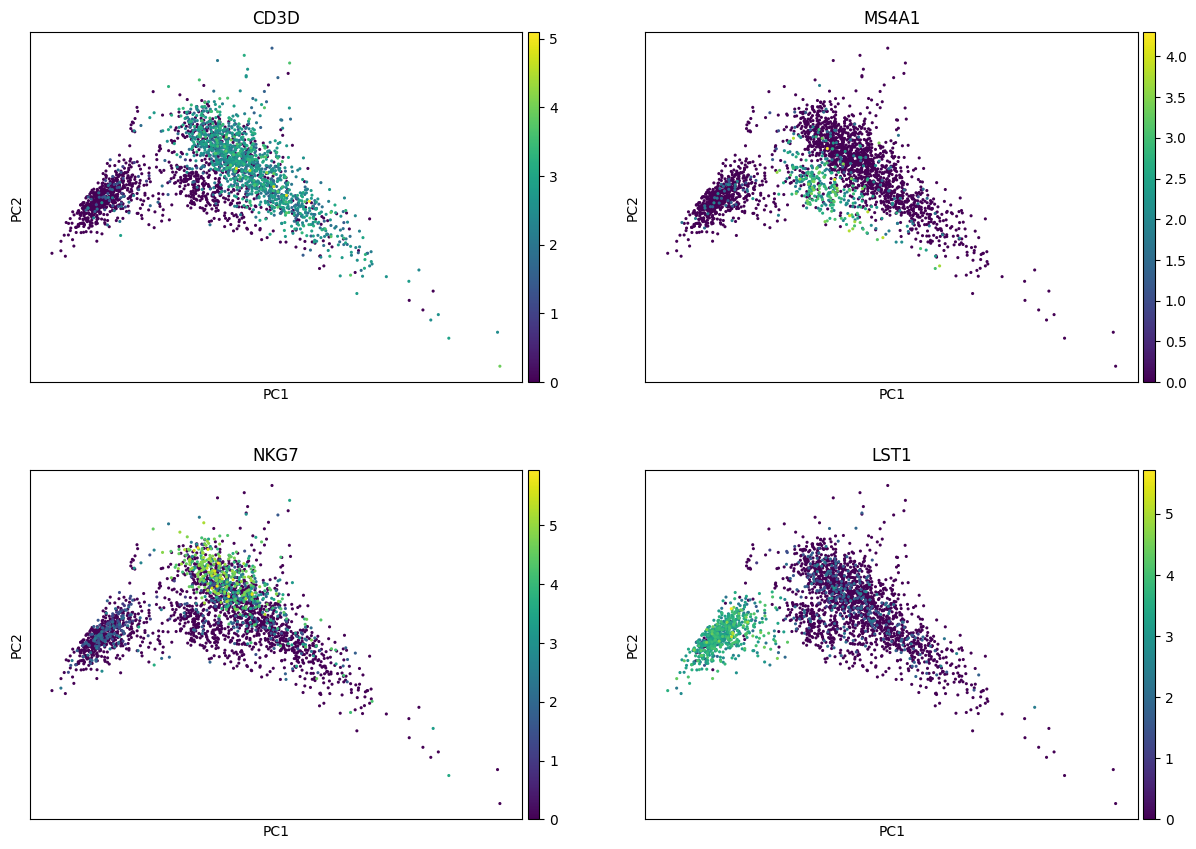


PCA: Без нормализации и log1p


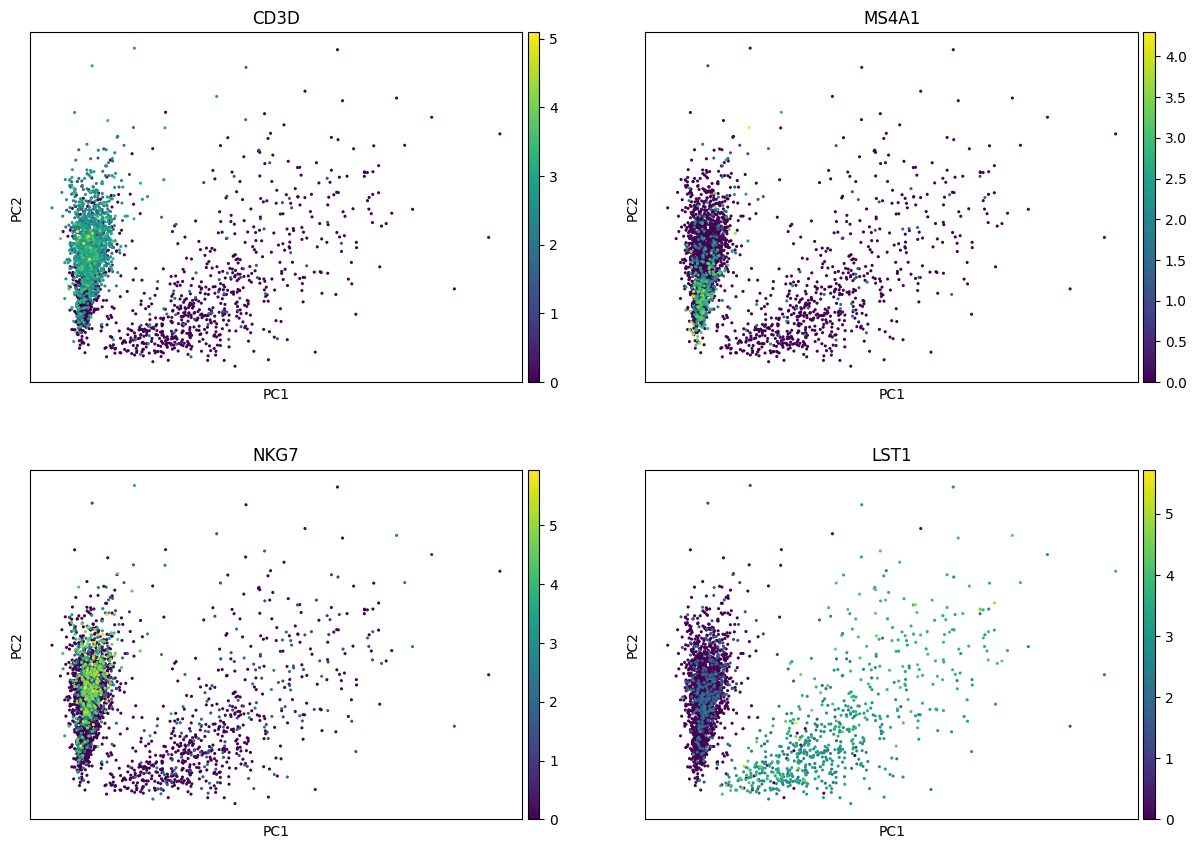


PCA: Нормализация + log1p + scale


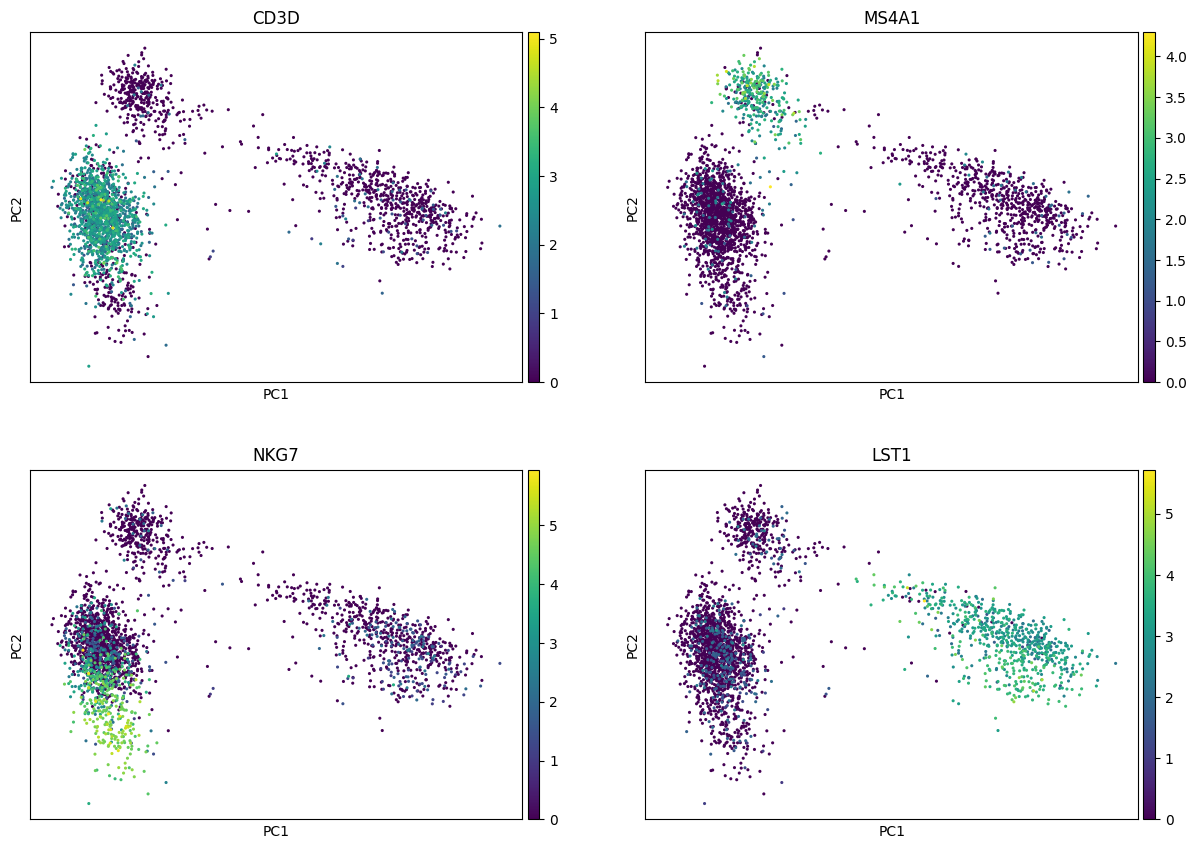

In [61]:
markers = ["CD3D", "MS4A1", "NKG7", "LST1"]

# Сохраняем одинаковые значения экспрессии маркеров
for name, data in datasets_pca7.items():
    data.raw = adata.copy()

# Строим PCA
for name, data in datasets_pca7.items():

    print(f"\nPCA: {name}")

    sc.pl.pca(
        data,
        color=markers,
        use_raw=True,
        ncols=2,
        size=20
    )

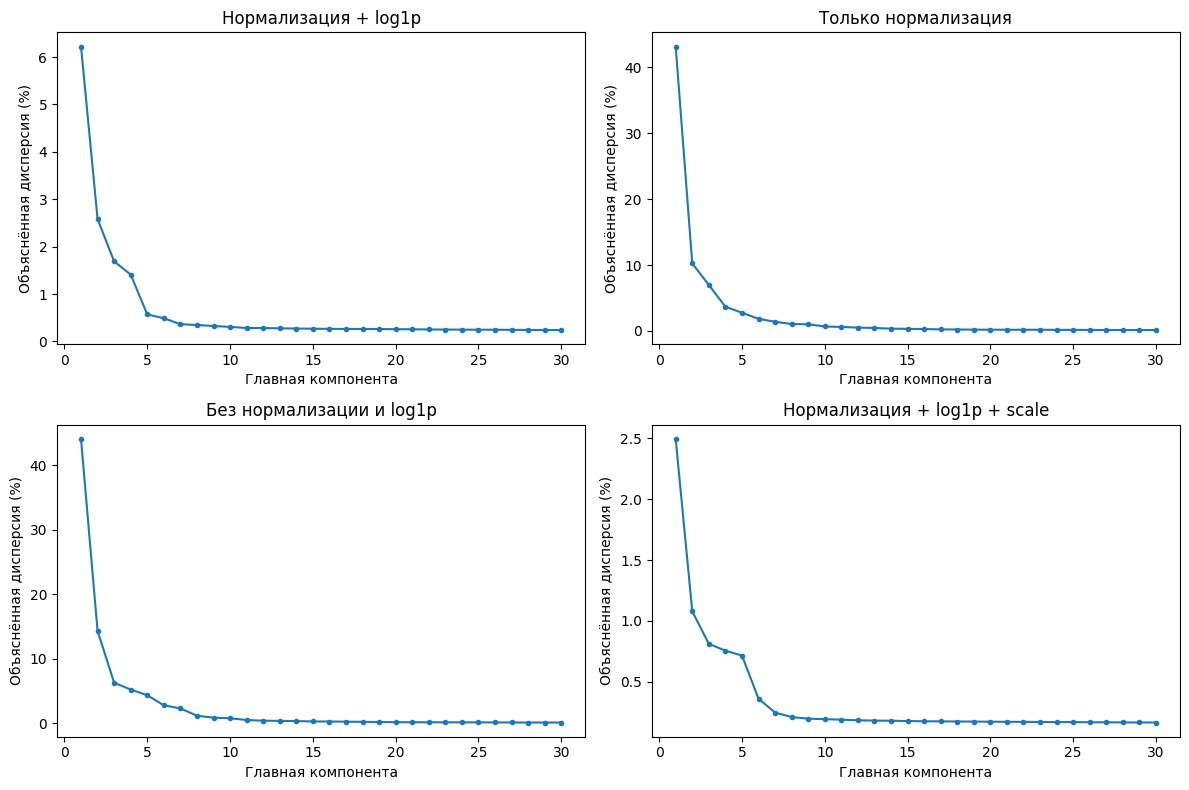

In [62]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (name, data) in zip(axes.flat, datasets_pca7.items()):

    variance = data.uns["pca"]["variance_ratio"] * 100

    ax.plot(
        range(1, len(variance) + 1),
        variance,
        marker="o",
        markersize=3
    )

    ax.set_title(name)
    ax.set_xlabel("Главная компонента")
    ax.set_ylabel("Объяснённая дисперсия (%)")

plt.tight_layout()
plt.show()

### Выводы по заданию 7

**1. Что сильнее влияет на PCA — нормализация или логарифмирование?**

Обе процедуры существенно влияют на PCA. Без нормализации расположение клеток может сильно зависеть от количества UMI. При одной нормализации отдельные высокоэкспрессируемые гены продолжают доминировать. Добавление `log1p` уменьшает их влияние и позволяет отчётливее различать клеточные популяции.

**2. Сильно ли помогает стандартизация (`scale`)?**

После стандартизации расположение клеток изменяется, но основные популяции сохраняются. В нашем анализе `scale` не даёт очевидного преимущества перед сочетанием нормализации и логарифмирования.

**3. Что даёт каждая процедура?**

- **Нормализация** — уменьшает влияние различий в суммарном количестве UMI между клетками.
- **Логарифмирование** — сжимает диапазон экспрессии и уменьшает влияние очень высоких значений.
- **Стандартизация** — центрирует экспрессию генов и приводит их к сопоставимому масштабу.

**4. Обязательно ли использовать все три процедуры перед PCA?**

Нет. Выбор обработки зависит от данных и метода анализа. Для PBMC 3k нормализация и `log1p` позволяют хорошо различать основные клеточные популяции. Стандартизация может быть полезна, но не является обязательной.

**--ю** предварительная обработка существенно влияет на PCA. Наиболее подходящий вариант следует выбирать с учётом биологической интерпретируемости результатов, а не только объяснённой дисперсии.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

In [55]:
# Создаём копию данных
adata_cycle = adata.copy()

# Гены S-фазы
s_genes = [
    "MCM5", "PCNA", "TYMS", "FEN1", "MCM2",
    "MCM4", "RRM1", "UNG", "GINS2", "MCM6",
    "CDCA7", "DTL", "RRM2", "CDC6", "RFC2"
]

# Гены G2/M-фазы
g2m_genes = [
    "HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5",
    "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2",
    "CKS1B", "MKI67", "CENPF", "TACC3", "CDC20"
]

# Оставляем только гены, присутствующие в данных
s_genes = [g for g in s_genes if g in adata_cycle.var_names]
g2m_genes = [g for g in g2m_genes if g in adata_cycle.var_names]

print("Генов S-фазы:", len(s_genes))
print("Генов G2/M-фазы:", len(g2m_genes))

Генов S-фазы: 14
Генов G2/M-фазы: 15


In [56]:
sc.tl.score_genes_cell_cycle(
    adata_cycle,
    s_genes=s_genes,
    g2m_genes=g2m_genes
)

# Проверяем результаты
adata_cycle.obs[
    ["S_score", "G2M_score", "phase"]
].head()

,S_score,G2M_score,phase
AAACATACAACCAC-1,0.147683,-0.052364,S
AAACATTGAGCTAC-1,-0.055586,-0.103365,G1
AAACATTGATCAGC-1,-0.044890,0.114980,G2M
AAACCGTGCTTCCG-1,0.067131,-0.177581,S
AAACCGTGTATGCG-1,-0.034518,-0.045457,G1


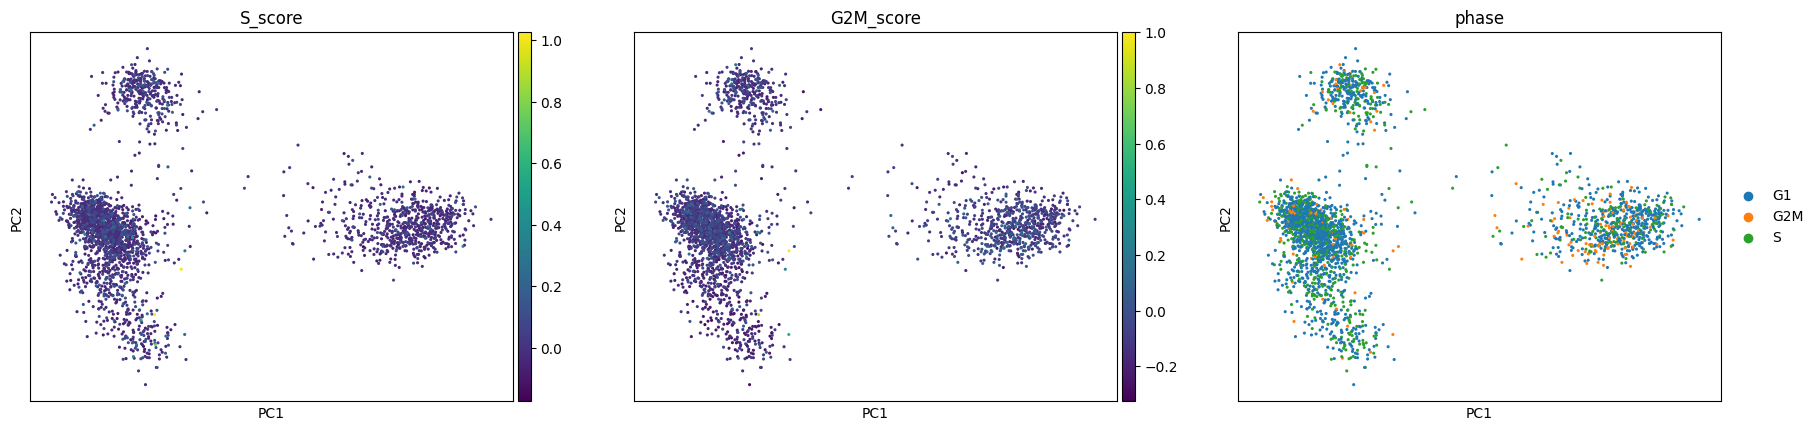

In [57]:
sc.pl.pca(
    adata_cycle,
    color=["S_score", "G2M_score", "phase"],
    ncols=3,
    size=20
)

### Выводы по дополнительному заданию

Для клеток PBMC 3k были рассчитаны `S_score` и `G2M_score`, а также определены предполагаемые фазы клеточного цикла.

На PCA клетки разных фаз преимущественно перемешаны и не образуют отдельных кластеров. Повышенная активность генов S- и G2/M-фаз наблюдается лишь у отдельных клеток.

**-->** клеточный цикл не оказывает выраженного влияния на первые две главные компоненты. Основные различия между клетками, вероятно, связаны с принадлежностью к разным иммунным популяциям. При этом использованные оценки фаз являются приблизительными.

Клетки одного типа могут находиться в разных фазах клеточного цикла, поэтому экспрессия генов, связанных с репликацией ДНК и делением, различается. Кроме того, на неё влияют состояние активации клетки и условия окружающей среды.